# Итоговое сравнение алгоритмов

Сопоставим результаты пяти лабораторных: KNN, линейных моделей, дерева, случайного леса и градиентного бустинга. Классификацию анкет и прогноз обращений рассмотрим отдельно. Для каждой задачи имеются исходная и выбранная по CV модель, каждая в библиотечной и собственной реализации.

Здесь не обучаем модели заново. Используем JSON из предыдущих работ, проверим сопоставимость исходных файлов, целей, тестов и фолдов. Общая исходная информация и одинаковые тестовые строки позволяют сравнивать результаты; подготовка признаков настроенных моделей может различаться.

## 1. Получение результатов

Используем рядом с ноутбуком результаты в формате JSON в каталоге `results`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

UPLOAD_RESULTS = False
FILENAMES = ["lab01_knn.json", "lab02_linear.json", "lab03_tree.json", "lab04_forest.json", "lab05_boosting.json"]

Выберем файлы и отобразим их источники. Для локального запуска из каталога `notebooks` проверим также соседний каталог `../results`.

In [2]:
uploaded = {}
if UPLOAD_RESULTS:
    from google.colab import files
    uploaded = files.upload()
reports, sources = [], []
for filename in FILENAMES:
    local = next((path for path in [Path("results")/filename, Path("../results")/filename] if path.exists()), None)
    if filename in uploaded:
        report, source = json.loads(uploaded[filename].decode("utf-8")), "Загруженный JSON"
    elif UPLOAD_RESULTS:
        raise ValueError(f"Не загружен обязательный файл {filename}")
    elif local is not None:
        report, source = json.loads(local.read_text(encoding="utf-8")), str(local)
    else:
        raise FileNotFoundError(f"Нет файла {filename}: сохраните JSON в results или включите UPLOAD_RESULTS")
    reports.append(report)
    sources.append({"Работа": report["lab"], "Источник": source})
display(pd.DataFrame(sources))

,Работа,Источник
0,1,results\lab01_knn.json
1,2,results\lab02_linear.json
2,3,results\lab03_tree.json
3,4,results\lab04_forest.json
4,5,results\lab05_boosting.json


## 2. Проверка условий сравнения

Проверим, что получены ровно пять разных работ и восемь разных вариантов в каждой. Сверим контрольные суммы исходных файлов и состава частей разработки, тестов и CV-фолдов. При несовпадении остановим построение общих оценок: сначала нужно согласовать версии данных или разбиения.

In [3]:
assert sorted(report["lab"] for report in reports) == [1, 2, 3, 4, 5]
reference = reports[0]
for report in reports:
    assert report["schema_version"] == 2
    assert len(report["results"]) == 8
    identities = {(r["task"], r["implementation"], r["variant"]) for r in report["results"]}
    assert identities == {(task, implementation, variant) for task in ["classification", "regression"]
                          for implementation in ["sklearn", "numpy"] for variant in ["baseline", "tuned"]}
    assert report["splits"] == reference["splits"], f"Разные разбиения в ЛР{report['lab']}"
    for task in ["classification", "regression"]:
        for key in ["sha256", "target"]:
            assert report["datasets"][task][key] == reference["datasets"][task][key], f"Разные данные/цели: ЛР{report['lab']}"
        folds_key = f"{task}_folds"
        assert report["cross_validation"][folds_key] == reference["cross_validation"][folds_key], f"Разные CV-фолды: ЛР{report['lab']}"
        assert report["cross_validation"][f"{task}_method"] == reference["cross_validation"][f"{task}_method"]
    for r in report["results"]:
        assert r["evaluation_split"] == "test"
        assert np.isfinite(list(r["metrics"].values())).all()
        assert len(r["cv_metrics"]["fold_scores"]) == 3
print("Проверены пять работ: общие данные, цели, разбиения и CV-фолды")

Проверены пять работ: общие данные, цели, разбиения и CV-фолды


Условия сравнения совпали. Различия предобработки покажем отдельно: исходный KNN использует числовой код района, а линейные и последующие модели кодируют район one-hot. Для линейных моделей удалена одна категория при наличии константы. Это сравнение исходных решений на одинаковой информации, а не изолированный эксперимент с полностью одинаковой числовой матрицей.

## 3. Общие таблицы

Для каждой модели покажем тестовые метрики и среднюю основную метрику CV с её стандартным отклонением. В классификации большее F1 лучше, в регрессии меньшая MAE лучше.

In [4]:
NAMES = {1: "KNN", 2: "Линейные модели", 3: "Дерево", 4: "Случайный лес", 5: "Бустинг"}
rows = []
for report in reports:
    for record in report["results"]:
        primary = "F1" if record["task"] == "classification" else "MAE"
        rows.append({"lab": report["lab"], "Алгоритм": NAMES[report["lab"]],
                     "task": record["task"], "implementation": record["implementation"], "variant": record["variant"],
                     **record["metrics"], "CV mean": record["cv_metrics"][primary+"_mean"],
                     "CV std": record["cv_metrics"][primary+"_std"],
                     "parameters": record["parameters"], "preprocessing": record["preprocessing"],
                     "input_features": record["input_features"]})
results = pd.DataFrame(rows).sort_values(["lab", "implementation", "variant"])
for task, metrics in [("classification", ["F1", "Balanced accuracy"]), ("regression", ["MAE", "RMSE"])]:
    print("Классификация" if task == "classification" else "Регрессия")
    display(results[results.task == task][["Алгоритм", "implementation", "variant", *metrics, "CV mean", "CV std"]].round(4))

,Алгоритм,implementation,variant,F1,Balanced accuracy,CV mean,CV std
1,KNN,numpy,baseline,0.8229,0.8108,0.7982,0.0126
3,KNN,numpy,tuned,0.8163,0.8096,0.8200,0.0278
0,KNN,sklearn,baseline,0.8229,0.8108,0.7982,0.0126
2,KNN,sklearn,tuned,0.8163,0.8096,0.8200,0.0278
10,Линейные модели,numpy,baseline,0.8358,0.8240,0.8183,0.0279
11,Линейные модели,numpy,tuned,0.8416,0.8290,0.8208,0.0182
8,Линейные модели,sklearn,baseline,0.8358,0.8240,0.8183,0.0279
9,Линейные модели,sklearn,tuned,0.8416,0.8290,0.8208,0.0182
18,Дерево,numpy,baseline,0.7802,0.7622,0.7867,0.0293
19,Дерево,numpy,tuned,0.7833,0.7647,0.7922,0.0284


,Алгоритм,implementation,variant,MAE,RMSE,CV mean,CV std
5,KNN,numpy,baseline,11.8526,22.1660,11.8780,0.5577
7,KNN,numpy,tuned,11.4356,21.3002,10.9681,0.2437
4,KNN,sklearn,baseline,11.8282,22.1680,11.8853,0.5505
6,KNN,sklearn,tuned,11.4354,21.3002,10.9681,0.2437
14,Линейные модели,numpy,baseline,10.8579,20.3526,10.6858,0.3249
15,Линейные модели,numpy,tuned,10.6861,20.2794,10.5691,0.2798
12,Линейные модели,sklearn,baseline,10.8579,20.3526,10.6858,0.3249
13,Линейные модели,sklearn,tuned,10.6861,20.2794,10.5691,0.2798
22,Дерево,numpy,baseline,11.1219,21.0603,11.1730,0.4298
23,Дерево,numpy,tuned,11.0499,21.0750,11.0781,0.3677


Классификация
Регрессия


Сопоставим, как изменилось тестовое качество после выбора настроек. Положительный выигрыш означает рост F1 или уменьшение MAE. Отрицательное значение сохраняем как результат эксперимента.

In [5]:
changes = []
for (task, lab, implementation), part in results.groupby(["task", "lab", "implementation"]):
    metric = "F1" if task == "classification" else "MAE"
    values = part.set_index("variant")
    before, after = values.loc["baseline", metric], values.loc["tuned", metric]
    gain = after - before if task == "classification" else before - after
    changes.append({"Задача": task, "Алгоритм": NAMES[lab], "Реализация": implementation,
                    "До": before, "После": after, "Выигрыш": gain})
display(pd.DataFrame(changes).round(4))

,Задача,Алгоритм,Реализация,До,После,Выигрыш
0,classification,KNN,numpy,0.8229,0.8163,-0.0066
1,classification,KNN,sklearn,0.8229,0.8163,-0.0066
2,classification,Линейные модели,numpy,0.8358,0.8416,0.0058
3,classification,Линейные модели,sklearn,0.8358,0.8416,0.0058
4,classification,Дерево,numpy,0.7802,0.7833,0.0030
5,classification,Дерево,sklearn,0.7802,0.7852,0.0049
6,classification,Случайный лес,numpy,0.8256,0.8390,0.0135
7,classification,Случайный лес,sklearn,0.8224,0.8281,0.0057
8,classification,Бустинг,numpy,0.8227,0.8244,0.0017
9,classification,Бустинг,sklearn,0.8198,0.8273,0.0075


## 4. Графическое сравнение

Отдельно покажем исходные и настроенные варианты двух реализаций. Все столбцы здесь относятся к тесту; модели выбирались по CV.

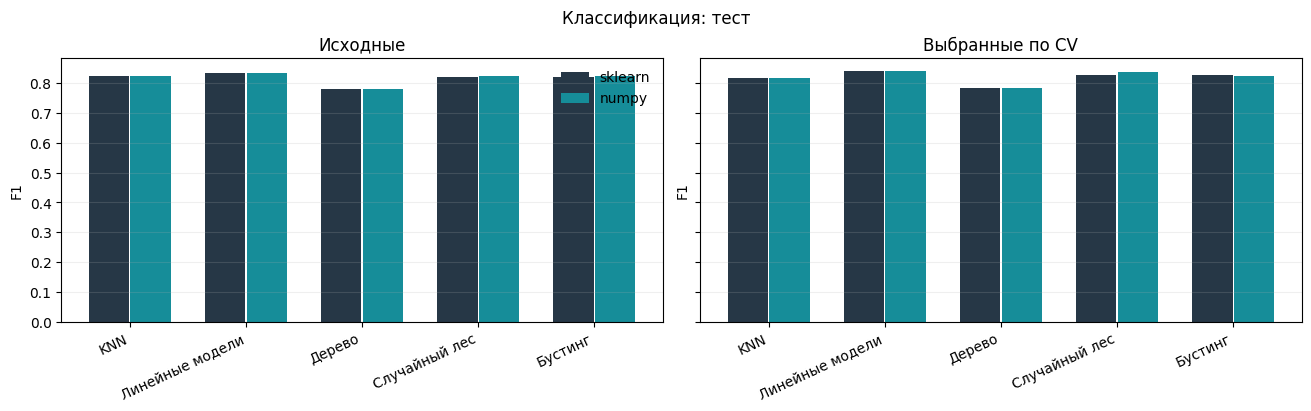

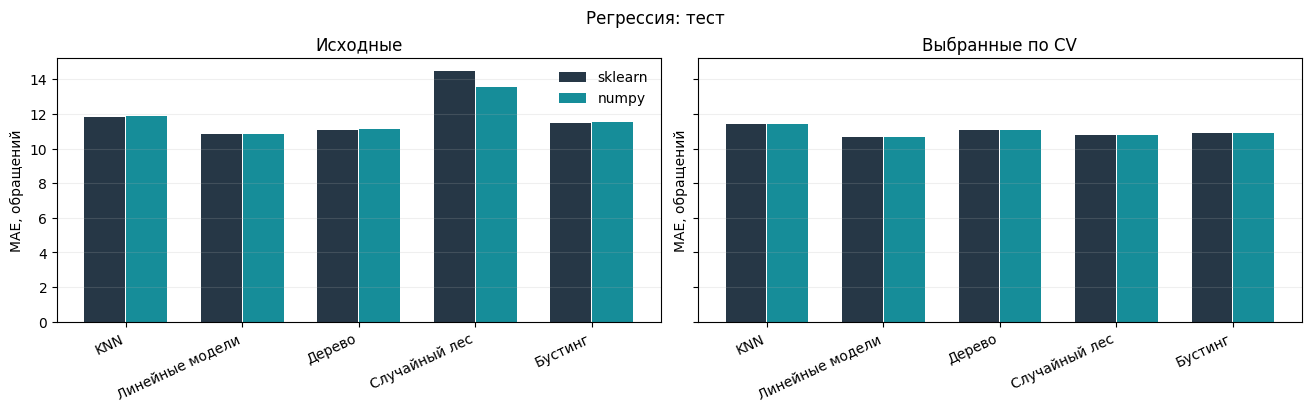

In [6]:
for task, metric, ylabel in [("classification", "F1", "F1"), ("regression", "MAE", "MAE, обращений")]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, layout="constrained")
    for ax, variant in zip(axes, ["baseline", "tuned"]):
        x = np.arange(5)
        for offset, implementation, color in [(-0.18, "sklearn", "#263746"), (0.18, "numpy", "#168d99")]:
            part = results[(results.task == task) & (results.variant == variant) & (results.implementation == implementation)].sort_values("lab")
            ax.bar(x+offset, part[metric], width=0.35, label=implementation, color=color)
        ax.set_xticks(x, [NAMES[i] for i in range(1,6)], rotation=25, ha="right")
        ax.set_title("Исходные" if variant == "baseline" else "Выбранные по CV")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.2)
    axes[0].legend(frameon=False)
    fig.suptitle("Классификация: тест" if task == "classification" else "Регрессия: тест")
    plt.show()

Теперь сопоставим среднее CV и тест выбранных библиотечных моделей. Вертикальные отрезки показывают одно стандартное отклонение по трём фолдам CV. Тестовая точка не имеет оценки неопределённости. Разница между CV и тестом может отражать состав выборок, временные изменения и адаптацию к фолдам при подборе.

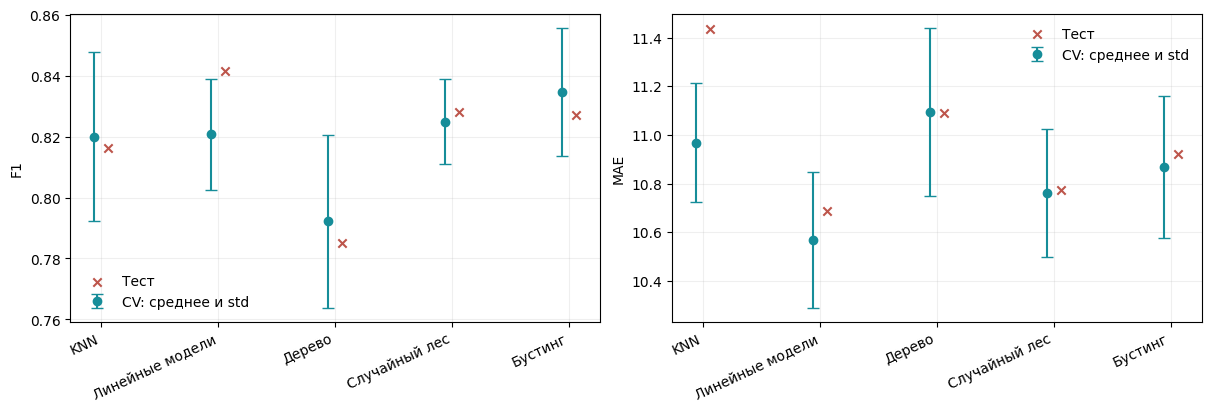

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, task, metric in zip(axes, ["classification", "regression"], ["F1", "MAE"]):
    part = results[(results.task == task) & (results.variant == "tuned") & (results.implementation == "sklearn")].sort_values("lab")
    x = np.arange(5)
    ax.errorbar(x-0.06, part["CV mean"], yerr=part["CV std"], fmt="o", capsize=4, label="CV: среднее и std", color="#168d99")
    ax.scatter(x+0.06, part[metric], marker="x", label="Тест", color="#bd554b")
    ax.set_xticks(x, part["Алгоритм"], rotation=25, ha="right")
    ax.set_ylabel(metric)
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
plt.show()

## 5. Подготовка данных и параметры

Укажем выбранные настройки, чтобы различия метрик можно было связать с условиями эксперимента. Полные сетки и выводы по гипотезам находятся в соответствующих лабораторных. Для KNN, линейных моделей и деревьев разумные способы подготовки могут отличаться.

In [8]:
preparation_rows = []
for _, row in results[(results.variant == "tuned") & (results.implementation == "sklearn")].iterrows():
    preparation_rows.append({"Алгоритм": row["Алгоритм"], "Задача": row.task,
                             "Параметры": json.dumps(row.parameters, ensure_ascii=False),
                             "Признаки": ", ".join(row.input_features),
                             "Предобработка": json.dumps(row.preprocessing, ensure_ascii=False)})
display(pd.DataFrame(preparation_rows))

,Алгоритм,Задача,Параметры,Признаки,Предобработка
0,KNN,classification,"{""n_neighbors"": 21, ""weights"": ""uniform"", ""p"": 2, ""threshold"": 0.5, ""metric"": ""euclidean""}","age, gender, education, country, ethnicity, nscore, escore, oscore, ascore, cscore, impulsive, ss","{""representation"": ""numeric"", ""standard_scaler"": true, ""categorical_features"": [], ""unknown_category"": ""all zeros"", ""area_encoding"": null}"
1,KNN,regression,"{""n_neighbors"": 31, ""weights"": ""uniform"", ""metric"": ""euclidean""}","area, lag_1, mean_3, sum_4, lag_52, week_sin, week_cos","{""standard_scaler"": true, ""area_encoding"": ""one_hot""}"
2,Линейные модели,classification,"{""C"": 0.1}","age, education, nscore, escore, oscore, ascore, cscore, impulsive, ss, gender, country, ethnicity","{""numeric_features"": [""age"", ""education"", ""nscore"", ""escore"", ""oscore"", ""ascore"", ""cscore"", ""impulsive"", ""ss""], ""standard_scaler"": true, ""categorical_features"": [""gender"", ""country"", ""ethnicity""], ""one_hot_drop_first"": true, ""unknown_category"": ""all zeros""}"
3,Линейные модели,regression,"{""alpha"": 10.0}","lag_1, mean_3, sum_4, lag_52, week_sin, week_cos, area","{""numeric_features"": [""lag_1"", ""mean_3"", ""sum_4"", ""lag_52"", ""week_sin"", ""week_cos""], ""standard_scaler"": true, ""categorical_features"": [""area""], ""one_hot_drop_first"": true, ""unknown_category"": ""all zeros""}"
4,Дерево,classification,"{""max_depth"": 7, ""min_samples_leaf"": 20}","age, gender, education, country, ethnicity, nscore, escore, oscore, ascore, cscore, impulsive, ss","{""numeric_features"": [""age"", ""gender"", ""education"", ""country"", ""ethnicity"", ""nscore"", ""escore"", ""oscore"", ""ascore"", ""cscore"", ""impulsive"", ""ss""], ""standard_scaler"": false, ""categorical_features"": [], ""one_hot_drop_first"": false, ""unknown_category"": ""all zeros""}"
5,Дерево,regression,"{""max_depth"": 7, ""min_samples_leaf"": 50}","lag_1, mean_3, sum_4, area","{""numeric_features"": [""lag_1"", ""mean_3"", ""sum_4""], ""standard_scaler"": false, ""categorical_features"": [""area""], ""one_hot_drop_first"": false, ""unknown_category"": ""all zeros""}"
6,Случайный лес,classification,"{""n_estimators"": 40, ""max_depth"": 7, ""min_samples_leaf"": 20, ""max_features"": ""sqrt""}","age, gender, education, country, ethnicity, nscore, escore, oscore, ascore, cscore, impulsive, ss","{""numeric_features"": [""age"", ""gender"", ""education"", ""country"", ""ethnicity"", ""nscore"", ""escore"", ""oscore"", ""ascore"", ""cscore"", ""impulsive"", ""ss""], ""standard_scaler"": false, ""categorical_features"": [], ""one_hot_drop_first"": false, ""unknown_category"": ""all zeros""}"
7,Случайный лес,regression,"{""n_estimators"": 40, ""max_depth"": 7, ""min_samples_leaf"": 20, ""max_features"": 1.0}","lag_1, mean_3, sum_4, lag_52, week_sin, week_cos, area","{""numeric_features"": [""lag_1"", ""mean_3"", ""sum_4"", ""lag_52"", ""week_sin"", ""week_cos""], ""standard_scaler"": false, ""categorical_features"": [""area""], ""one_hot_drop_first"": false, ""unknown_category"": ""all zeros""}"
8,Бустинг,classification,"{""n_estimators"": 60, ""learning_rate"": 0.1, ""max_depth"": 2, ""min_samples_leaf"": 20}","age, education, nscore, escore, oscore, ascore, cscore, impulsive, ss, gender, country, ethnicity","{""numeric_features"": [""age"", ""education"", ""nscore"", ""escore"", ""oscore"", ""ascore"", ""cscore"", ""impulsive"", ""ss""], ""standard_scaler"": false, ""categorical_features"": [""gender"", ""country"", ""ethnicity""], ""one_hot_drop_first"": false, ""unknown_category"": ""all zeros""}"
9,Бустинг,regression,"{""n_estimators"": 60, ""learning_rate"": 0.1, ""max_depth"": 2, ""min_samples_leaf"": 20}","lag_1, mean_3, sum_4, lag_52, week_sin, week_cos, area","{""numeric_features"": [""lag_1"", ""mean_3"", ""sum_4"", ""lag_52"", ""week_sin"", ""week_cos""], ""standard_scaler"": false, ""categorical_features"": [""area""], ""one_hot_drop_fi

## 6. Выводы

Сначала назовём варианты с лучшей средней CV-оценкой среди заранее настроенных моделей. Это правило выбора не использует тест. Затем отдельно покажем, какие модели получили максимальный F1 или минимальную MAE на общем тесте; эти значения являются описанием результатов, а не новым подбором.

In [9]:
for task, metric, maximum in [("classification", "F1", True), ("regression", "MAE", False)]:
    part = results[(results.task == task) & (results.variant == "tuned") & (results.implementation == "sklearn")]
    cv_index = part["CV mean"].idxmax() if maximum else part["CV mean"].idxmin()
    test_index = part[metric].idxmax() if maximum else part[metric].idxmin()
    chosen, descriptive = part.loc[cv_index], part.loc[test_index]
    print(task)
    print("Выбор по среднему CV:", chosen["Алгоритм"], round(chosen["CV mean"],4))
    print("Лучшая тестовая оценка среди выбранных библиотечных вариантов:", descriptive["Алгоритм"], round(descriptive[metric],4))

classification
Выбор по среднему CV: Бустинг 0.8345
Лучшая тестовая оценка среди выбранных библиотечных вариантов: Линейные модели 0.8416
regression
Выбор по среднему CV: Линейные модели 10.5691
Лучшая тестовая оценка среди выбранных библиотечных вариантов: Линейные модели 10.6861


Сопоставили пять алгоритмов на общих данных, тестах и CV-фолдах. Для каждого алгоритма рассмотрели исходный и выбранный по CV варианты, а также две реализации. Подготовка признаков указана в таблицах, поэтому результаты настроенных моделей относятся к решениям целиком: преобразованиям и алгоритму.

В классификации по среднему CV среди настроенных библиотечных моделей выбирается «Бустинг» с F1 = 0.8345. Лучшая тестовая оценка среди этих вариантов у «Линейные модели»: F1 = 0.8416. Это описательное сравнение на одном тесте; небольшие различия не доказывают устойчивого превосходства модели.

В регрессии по среднему CV среди настроенных библиотечных моделей выбирается «Линейные модели» с MAE = 10.5691. Лучшая тестовая оценка среди этих вариантов у «Линейные модели»: MAE = 10.6861. Это описательное сравнение на одном тесте; небольшие различия не доказывают устойчивого превосходства модели.

Настройка оценивается отдельно для каждой задачи. Рост среднего качества на CV не гарантирует улучшения тестовой оценки, поэтому отрицательные результаты сохранены. Средние по трём фолдам рассмотрены вместе с их разбросом; для временных данных этот разброс также отражает различия проверочных годов.

Собственные линейные модели решают те же задачи оптимизации, что sklearn. Собственные деревья и ансамбли используют ограниченные пороги, поэтому отличия прогнозов ожидаемы. Для обеих реализаций сохранены одинаковые признаки и общие параметры соответствующего варианта; проверка формул приведена в лабораторных.

Выводы ограничены 377 тестовыми анкетами и 3696 районными неделями одного исторического периода.